# 04 — Filtragem, suavização e ruído

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 04/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 04/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor.


### Materiais complementares

- [Guia Técnico](./reference_materials/04_filtragem_ruido.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_filtragem_ruido.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Comparar filtros de média, gaussiano e mediana sob ruído controlado.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Filtros lineares combinam intensidades com um núcleo espacial. A suavização gaussiana atenua frequências altas, reduzindo ruído, mas pode borrar bordas. A mediana é não linear e robusta a ruído impulsivo. Para avaliação, compare métricas com uma referência conhecida; sem ground truth, inspecione artefatos.

### Conceito matemático

$$I_{out}(x,y)=\sum_{i,j}K(i,j)I(x-i,y-j)$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.data import camera
from scipy.ndimage import gaussian_filter,median_filter,uniform_filter
rng=np.random.default_rng(13);ref=camera().astype(float)/255
noisy=ref.copy();mask=rng.random(ref.shape)<.045;noisy[mask]=rng.choice([0.,1.],mask.sum())
results={'ruidosa':noisy,'média':uniform_filter(noisy,size=3),'gaussiana':gaussian_filter(noisy,1),'mediana':median_filter(noisy,size=3)}
for k,v in results.items():print(k,round(np.mean((v-ref)**2),5))

ruidosa 0.0151
média 0.00302
gaussiana 0.00253
mediana 0.00096


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

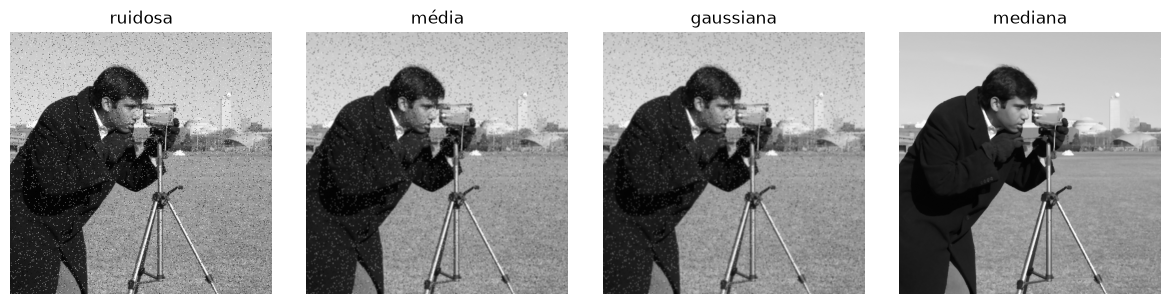

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,4,figsize=(12,3))
for a,(name,img) in zip(ax,results.items()):a.imshow(img,cmap='gray',vmin=0,vmax=1);a.set_title(name);a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

O filtro mediano costuma funcionar bem para sal-e-pimenta; a escolha depende do modelo de ruído.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Por que um filtro grande pode prejudicar bordas?

**Resolução comentada:** Porque faz a média de pixels pertencentes a regiões diferentes, suavizando descontinuidades.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Comparações devem usar mesma imagem e parâmetros explicitados; não escolher filtro apenas pela estética.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Comparar filtros de média, gaussiano e mediana sob ruído controlado.
- **Mecanismo:** Filtros lineares combinam intensidades com um núcleo espacial.
- **Equação:** $I_{out}(x,y)=\sum_{i,j}K(i,j)I(x-i,y-j)$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** ruído vs detalhe. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **ruído vs detalhe** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **ruído vs detalhe** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
